# 01 — Análise Exploratória (EDA): Saúde Fetal

## Problema
Classificar exames de **cardiotocografia (CTG)** em três classes de saúde fetal,
atribuídas por especialistas: **1 = Normal**, **2 = Suspeito**, **3 = Patológico**.

| Item | Definição |
|---|---|
| Unidade de observação | Um exame de CTG (uma linha). Não há identificador de paciente. |
| Target | `fetal_health` (multiclasse, ordinal em gravidade) |
| Classe crítica | **Patológico (3)**: um falso negativo é o erro de maior custo clínico |
| Momento da previsão | Após o registro do exame, a partir das medidas extraídas do traçado |
| Dados | `data/raw/fetal_health_reduced.csv` — versão reduzida (4 features) do dataset *Fetal Health Classification*. Origem exata da redução e unidades: **a confirmar** |

> **Saúde e ética:** o dataset é público e não contém identificadores pessoais.
> Nenhuma conclusão aqui é causal nem indica prontidão clínica.

## Protocolo anti-leakage desta EDA
1. Checagens de **integridade** (schema, ausentes, duplicatas) usam a base completa — não aprendem padrões.
2. O split TRAIN/TEST é criado (ou reaproveitado) **antes** das análises que orientam a modelagem.
3. Distribuições, associações, faixas e importâncias usam **somente o TRAIN**.

## 1. Setup

In [1]:
# Bootstrap: localiza a raiz do projeto e torna `src/` importável
# (funciona com ou sem `pip install -e .`).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print("Raiz do projeto:", ROOT)

Raiz do projeto: c:\Users\mateu_g1p9kd2\OneDrive\Documentos\GitHub\Saude-Fetal-pos-graduacao


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from saude_fetal import analysis
from saude_fetal.config import FIGURES_DIR, METRICS_DIR, ensure_dirs, load_config, resolve_path
from saude_fetal.data import file_sha256, load_raw, load_split, make_split
from saude_fetal.evaluation import class_names_from_cfg

ensure_dirs()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

data_cfg = load_config("data")
FEATURES = data_cfg["features"]
TARGET = data_cfg["target"]["column"]
CLASS_NAMES = class_names_from_cfg(data_cfg)  # {1: 'Normal', 2: 'Suspeito', 3: 'Patologico'}
CLASS_COLORS = {1: "#2ca02c", 2: "#ff7f0e", 3: "#d62728"}
SEED = data_cfg["split"]["random_state"]


def save_fig(fig, name):
    """Salva a figura em reports/figures com prefixo eda_."""
    path = FIGURES_DIR / f"eda_{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    return path

## 2. Carregamento e validação do schema (base completa)

In [3]:
raw_path = resolve_path(data_cfg["dataset"]["raw_path"])
df = load_raw(data_cfg)  # valida colunas, tipos, finitude, não negatividade e classes
print("Arquivo:", raw_path.relative_to(ROOT))
print("SHA256:", file_sha256(raw_path))
print("Dimensões:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Arquivo: data\raw\fetal_health_reduced.csv
SHA256: f5300904f5c7de722c7e96944fc5ab9b21c9ab5126102c84b1933994723e2594
Dimensões: (2126, 5)


,severe_decelerations,accelerations,fetal_movement,uterine_contractions,fetal_health
0,0.0000,0.0000,0.0000,0.0000,2
1,0.0000,6.0000,0.0000,6.0000,1
2,0.0000,3.0000,0.0000,8.0000,1
3,0.0000,3.0000,0.0000,8.0000,1
4,0.0000,7.0000,0.0000,8.0000,1


,dtype
severe_decelerations,float64
accelerations,float64
fetal_movement,float64
uterine_contractions,float64
fetal_health,int64


### Dicionário das features

Descrições conforme o dataset original de CTG. As **unidades desta versão reduzida
precisam ser confirmadas**: no dataset original essas medidas são taxas *por segundo*
(valores como 0,003); aqui aparecem valores inteiros, o que sugere uma reescala
(ex.: contagem por 1000 s). A tabela de resumo abaixo ajuda a verificar.

| Feature | Descrição (dataset original) |
|---|---|
| `severe_decelerations` | Desacelerações graves da frequência cardíaca fetal |
| `accelerations` | Acelerações da frequência cardíaca fetal |
| `fetal_movement` | Movimentos fetais |
| `uterine_contractions` | Contrações uterinas |
| `fetal_health` | Target: 1 Normal, 2 Suspeito, 3 Patológico |

## 3. Qualidade dos dados (integridade — base completa)

In [4]:
summary_all = analysis.feature_summary(df, FEATURES)
display(summary_all)
print("Ausentes por coluna:")
display(df.isna().sum().to_frame("missing").T)

,dtype,n,missing,zeros_prop,n_unique,min,p25,median,p75,p99,max,mean,std,skew
feature,,,,,,,,,,,,,,
severe_decelerations,float64,2126,0,0.9967,2,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0033,0.0573,17.3535
accelerations,float64,2126,0,0.4205,20,0.0000,0.0000,2.0000,6.0000,15.0000,19.0000,3.1783,3.8656,1.2044
fetal_movement,float64,2126,0,0.6167,102,0.0000,0.0000,0.0000,3.0000,338.7500,481.0000,9.4807,46.6658,7.8115
uterine_contractions,float64,2126,0,0.1562,16,0.0000,2.0000,4.0000,7.0000,11.0000,15.0000,4.3664,2.9461,0.1593


Ausentes por coluna:


,severe_decelerations,accelerations,fetal_movement,uterine_contractions,fetal_health
missing,0,0,0,0,0


In [5]:
dup = analysis.duplicate_report(df, FEATURES, TARGET)
display(pd.Series(dup, name="valor").to_frame())

,valor
linhas,2126
duplicadas_features_e_target,1337
duplicadas_somente_features,1439
combinacoes_unicas_de_features,687
combinacoes_com_rotulos_conflitantes,80


**Leitura das duplicatas:** com apenas 4 features discretas, exames distintos podem
ter exatamente os mesmos valores. Por isso linhas repetidas **não são removidas**:
não há identificador que prove que são o mesmo exame. Combinações de features com
rótulos conflitantes indicam um **limite de separabilidade** — nenhum modelo que use
só essas 4 variáveis consegue acertar todos esses casos.

## 4. Split TRAIN/TEST (persistido, estratificado)

In [6]:
manifest = make_split(data_cfg)  # cria na 1ª execução; depois só reaproveita
X_train, y_train = load_split("train", data_cfg)
print(
    json.dumps(
        {k: manifest[k] for k in ("test_size", "random_state", "n_rows", "class_counts")},
        indent=2,
    )
)
# A partir daqui, apenas X_train / y_train. O TEST não é carregado neste notebook.
train = X_train.assign(**{TARGET: y_train})

{
  "test_size": 0.2,
  "random_state": 42,
  "n_rows": {
    "raw": 2126,
    "train": 1700,
    "test": 426
  },
  "class_counts": {
    "train": {
      "1": 1323,
      "2": 236,
      "3": 141
    },
    "test": {
      "1": 332,
      "2": 59,
      "3": 35
    }
  }
}


## 5. Distribuição do target

,classe,n,prop,n_train,prop_train
fetal_health,,,,,
1,Normal,1655,0.7785,1323,0.7782
2,Suspeito,295,0.1388,236,0.1388
3,Patologico,176,0.0828,141,0.0829


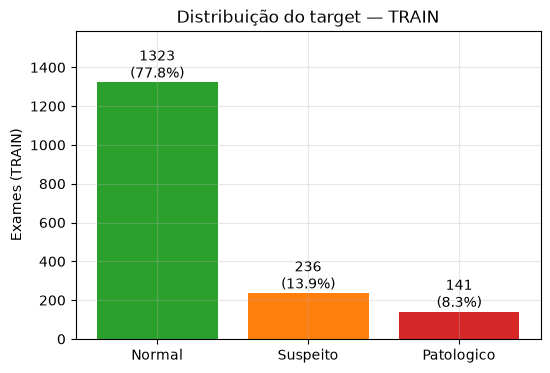

In [7]:
dist_all = analysis.target_distribution(df[TARGET], CLASS_NAMES)
dist_train = analysis.target_distribution(y_train, CLASS_NAMES)
target_table = dist_all.join(dist_train[["n", "prop"]], rsuffix="_train")
display(target_table)
target_table.to_csv(METRICS_DIR / "eda_target_distribution.csv")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    dist_train["classe"],
    dist_train["n"],
    color=[CLASS_COLORS[c] for c in dist_train.index],
)
for b, n, p in zip(bars, dist_train["n"], dist_train["prop"]):
    ax.text(
        b.get_x() + b.get_width() / 2,
        b.get_height(),
        f"{n}\n({p:.1%})",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Exames (TRAIN)")
ax.set_title("Distribuição do target — TRAIN")
ax.set_ylim(0, dist_train["n"].max() * 1.2)
save_fig(fig, "target_distribution")
plt.show()

## 6. Distribuição das features (TRAIN)

In [8]:
summary_train = analysis.feature_summary(train, FEATURES)
display(summary_train)
summary_train.to_csv(METRICS_DIR / "eda_feature_summary_train.csv")

,dtype,n,missing,zeros_prop,n_unique,min,p25,median,p75,p99,max,mean,std,skew
feature,,,,,,,,,,,,,,
severe_decelerations,float64,1700,0,0.9971,2,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0029,0.0542,18.3739
accelerations,float64,1700,0,0.4171,19,0.0000,0.0000,2.0000,6.0000,15.0000,18.0000,3.1959,3.8511,1.1808
fetal_movement,float64,1700,0,0.6171,94,0.0000,0.0000,0.0000,3.0000,346.0000,477.0000,9.9347,47.9815,7.5374
uterine_contractions,float64,1700,0,0.1535,15,0.0000,2.0000,5.0000,7.0000,11.0000,14.0000,4.3618,2.9246,0.1297


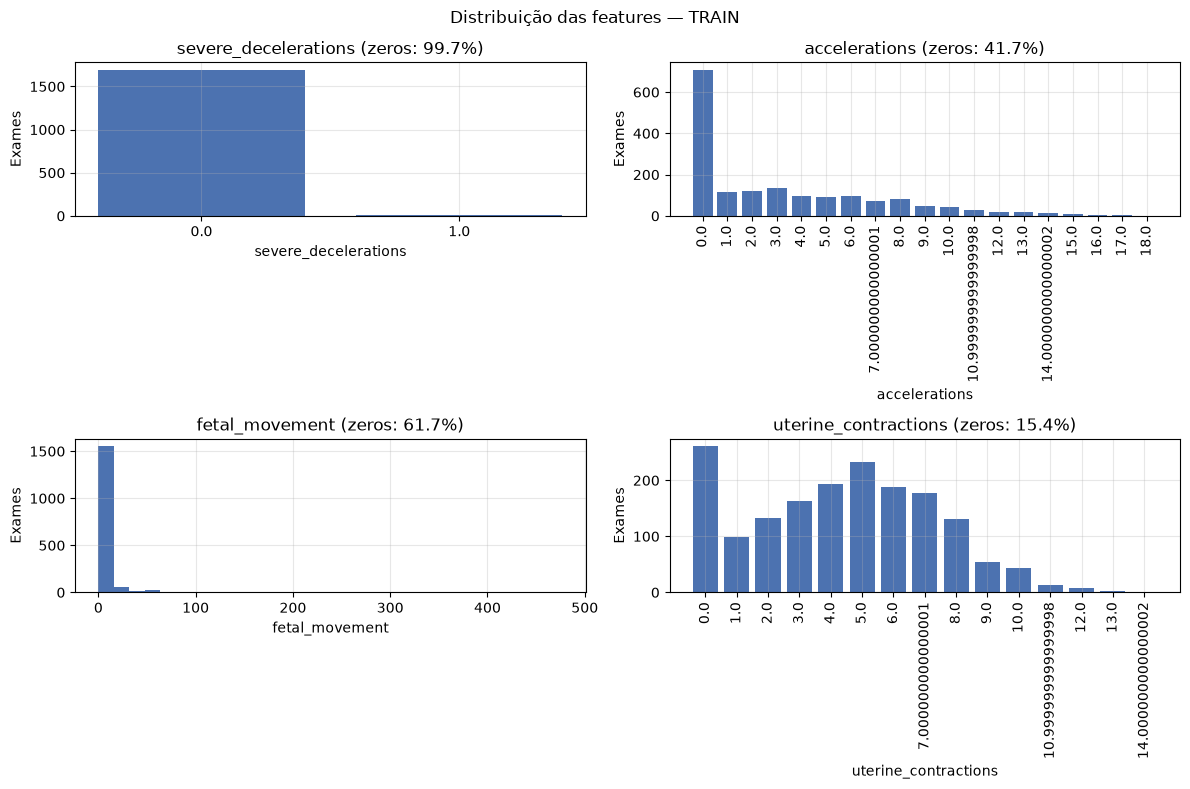

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    values = train[col]
    if values.nunique() <= 25:  # discreta: barras por valor
        counts = values.value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color="#4c72b0")
        ax.set_xlabel(col)
        if len(counts) > 12:
            ax.tick_params(axis="x", rotation=90)
    else:
        ax.hist(values, bins=30, color="#4c72b0")
        ax.set_xlabel(col)
    ax.set_ylabel("Exames")
    ax.set_title(f"{col} (zeros: {(values == 0).mean():.1%})")
fig.suptitle("Distribuição das features — TRAIN")
fig.tight_layout()
save_fig(fig, "feature_distributions")
plt.show()

### 6.1 Distribuição por classe (box plots, TRAIN)

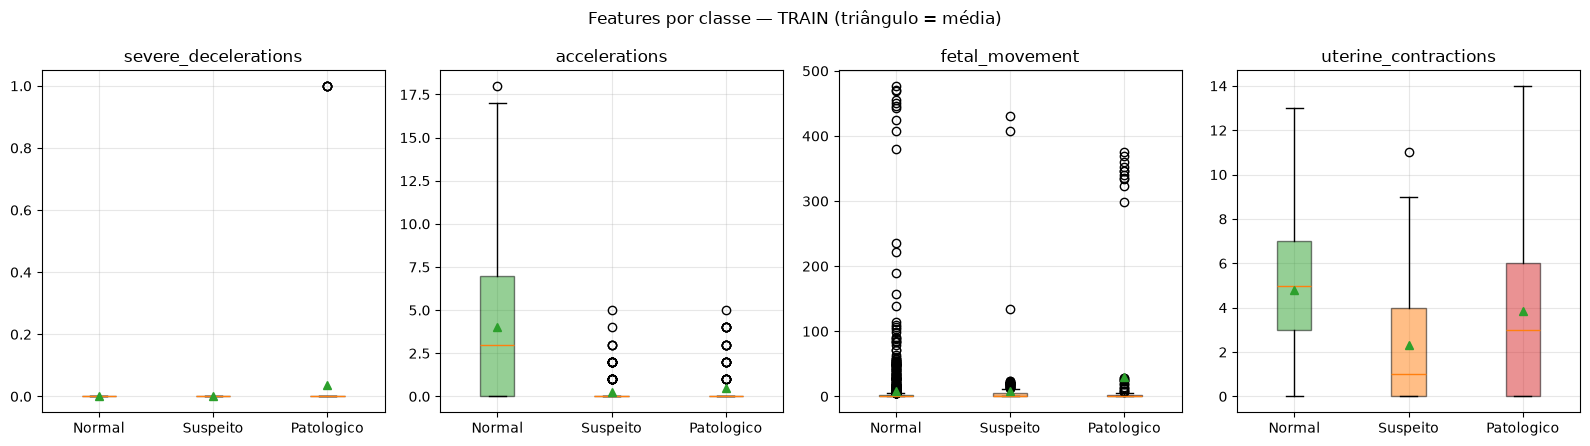

severe_decelerations        accelerations        fetal_movement  \
                             mean median          mean median           mean   
fetal_health                                                                   
Normal                     0.0000 0.0000        4.0136 3.0000         8.2608   
Suspeito                   0.0000 0.0000        0.2415 0.0000         7.8517   
Patologico                 0.0355 0.0000        0.4681 0.0000        29.1277   

                    uterine_contractions         
             median                 mean median  
fetal_health                                     
Normal       0.0000               4.7808 5.0000  
Suspeito     0.0000               2.3178 1.0000  
Patologico   1.0000               3.8511 3.0000

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, FEATURES):
    groups = [train.loc[train[TARGET] == c, col] for c in CLASS_NAMES]
    bp = ax.boxplot(groups, patch_artist=True, showmeans=True)
    ax.set_xticks(range(1, len(CLASS_NAMES) + 1), list(CLASS_NAMES.values()))
    for patch, c in zip(bp["boxes"], CLASS_NAMES):
        patch.set_facecolor(CLASS_COLORS[c])
        patch.set_alpha(0.5)
    ax.set_title(col)
fig.suptitle("Features por classe — TRAIN (triângulo = média)")
fig.tight_layout()
save_fig(fig, "boxplots_by_class")
plt.show()

means = train.groupby(TARGET)[FEATURES].agg(["mean", "median"]).rename(index=CLASS_NAMES)
display(means)

## 7. Taxa do desfecho por faixa (TRAIN)

Faixas aprendidas no TRAIN (quantis; ou os próprios valores quando há poucos valores
distintos). `n_total` é o denominador de cada linha; taxas em escala 0–1.
Faixas com poucos exames não devem ser interpretadas como padrão estável.

In [11]:
rate_tables = {}
for col in FEATURES:
    tab = analysis.rate_by_bins(X_train, y_train, col, CLASS_NAMES, max_bins=5)
    rate_tables[col] = tab
    print(f"\n=== {col} ===")
    display(tab)
pd.concat(rate_tables, names=["feature"]).to_csv(METRICS_DIR / "eda_rate_by_bins_train.csv")


=== severe_decelerations ===


,n_total,n_Normal,n_Suspeito,n_Patologico,taxa_Normal,taxa_Suspeito,taxa_Patologico
severe_decelerations,,,,,,,
0.0,1695,1323,236,136,0.7805,0.1392,0.0802
1.0,5,0,0,5,0.0000,0.0000,1.0000



=== accelerations ===


,n_total,n_Normal,n_Suspeito,n_Patologico,taxa_Normal,taxa_Suspeito,taxa_Patologico
accelerations,,,,,,,
"(-inf, 3.0]",1080,712,234,134,0.6593,0.2167,0.1241
"(3.0, 7.0]",349,340,2,7,0.9742,0.0057,0.0201
"(7.0, inf]",271,271,0,0,1.0000,0.0000,0.0000



=== fetal_movement ===


,n_total,n_Normal,n_Suspeito,n_Patologico,taxa_Normal,taxa_Suspeito,taxa_Patologico
fetal_movement,,,,,,,
"(-inf, 4.0]",1369,1084,169,116,0.7918,0.1234,0.0847
"(4.0, inf]",331,239,67,25,0.7221,0.2024,0.0755



=== uterine_contractions ===


,n_total,n_Normal,n_Suspeito,n_Patologico,taxa_Normal,taxa_Suspeito,taxa_Patologico
uterine_contractions,,,,,,,
"(-inf, 1.0]",359,188,120,51,0.5237,0.3343,0.1421
"(1.0, 4.0]",489,398,59,32,0.8139,0.1207,0.0654
"(4.0, 5.0]",233,203,20,10,0.8712,0.0858,0.0429
"(5.0, 7.0]",366,316,28,22,0.8634,0.0765,0.0601
"(7.0, inf]",253,218,9,26,0.8617,0.0356,0.1028


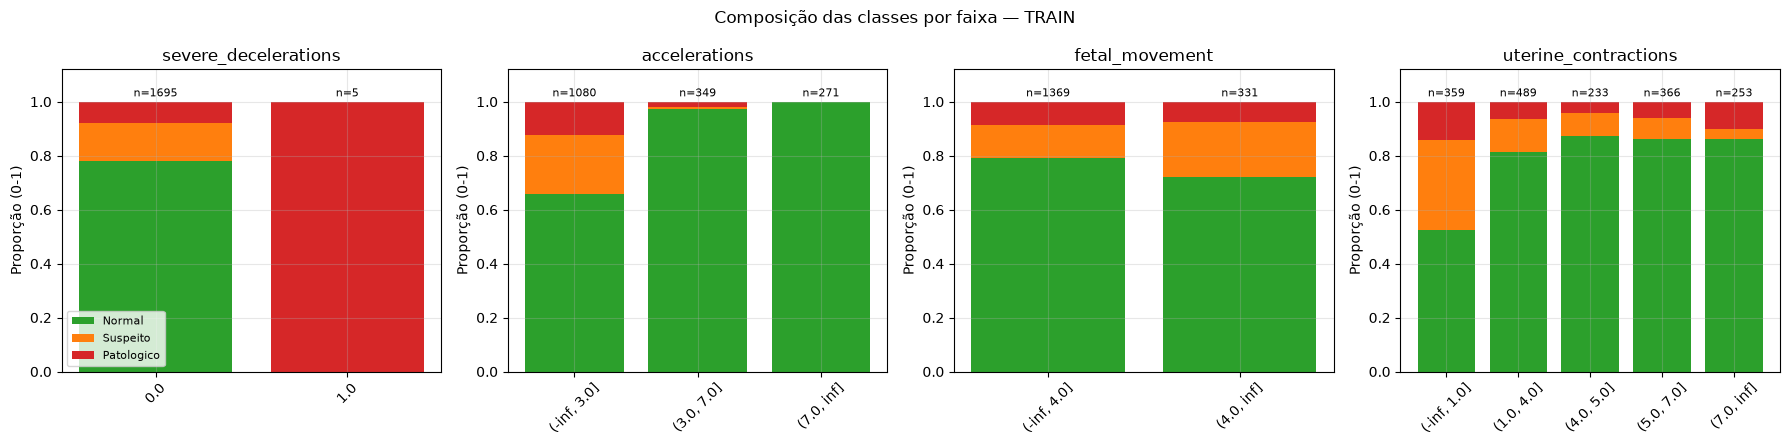

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (col, tab) in zip(axes, rate_tables.items()):
    bottom = np.zeros(len(tab))
    for c, name in CLASS_NAMES.items():
        vals = tab[f"taxa_{name}"].to_numpy()
        ax.bar(tab.index, vals, bottom=bottom, color=CLASS_COLORS[c], label=name)
        bottom += vals
    for i, n in enumerate(tab["n_total"]):
        ax.text(i, 1.01, f"n={n}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, 1.12)
    ax.set_title(col)
    ax.set_ylabel("Proporção (0-1)")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Composição das classes por faixa — TRAIN")
fig.tight_layout()
save_fig(fig, "class_rate_by_bins")
plt.show()

## 8. Correlação entre features (redundância — TRAIN)

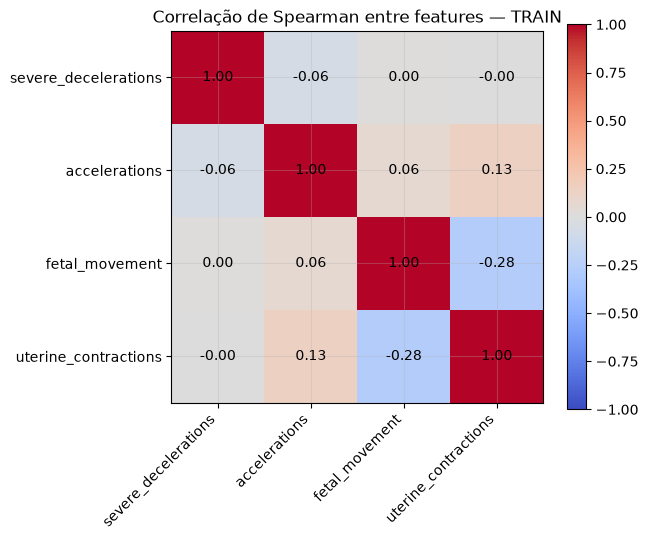

In [13]:
corr = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax)
ax.set_title("Correlação de Spearman entre features — TRAIN")
save_fig(fig, "feature_correlation_spearman")
plt.show()

## 9. Associação com o target × importância preditiva (TRAIN)

- **Spearman** com o target ordinal (Normal < Suspeito < Patológico): associação monotônica com a gravidade.
- **Informação mútua**: dependência possivelmente não linear (sem sinal).
- **Permutation importance**: queda do F1 macro ao embaralhar a feature, medida no
  fold de validação de uma CV estratificada **dentro do TRAIN** (Random Forest exploratório,
  parâmetros padrão — não é o modelo final).

> Correlação alta não implica importância preditiva, e vice-versa. Nenhuma das duas implica causalidade.

In [14]:
from sklearn.ensemble import RandomForestClassifier

assoc = analysis.association_table(X_train, y_train, random_state=SEED)
perm = analysis.cv_permutation_importance(
    RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    X_train,
    y_train,
    n_splits=5,
    scoring="f1_macro",
    n_repeats=10,
    random_state=SEED,
)
assoc_imp = assoc.join(perm).sort_values("perm_importance_mean", ascending=False)
display(assoc_imp)
assoc_imp.to_csv(METRICS_DIR / "eda_association_vs_importance_train.csv")

,spearman,abs_spearman,mutual_info,perm_importance_mean,perm_importance_std
accelerations,-0.4586,0.4586,0.1401,0.1430,0.0116
uterine_contractions,-0.2600,0.2600,0.0511,0.1271,0.0459
fetal_movement,0.1224,0.1224,0.0431,0.1146,0.0479
severe_decelerations,0.1190,0.1190,0.0000,0.0117,0.0112


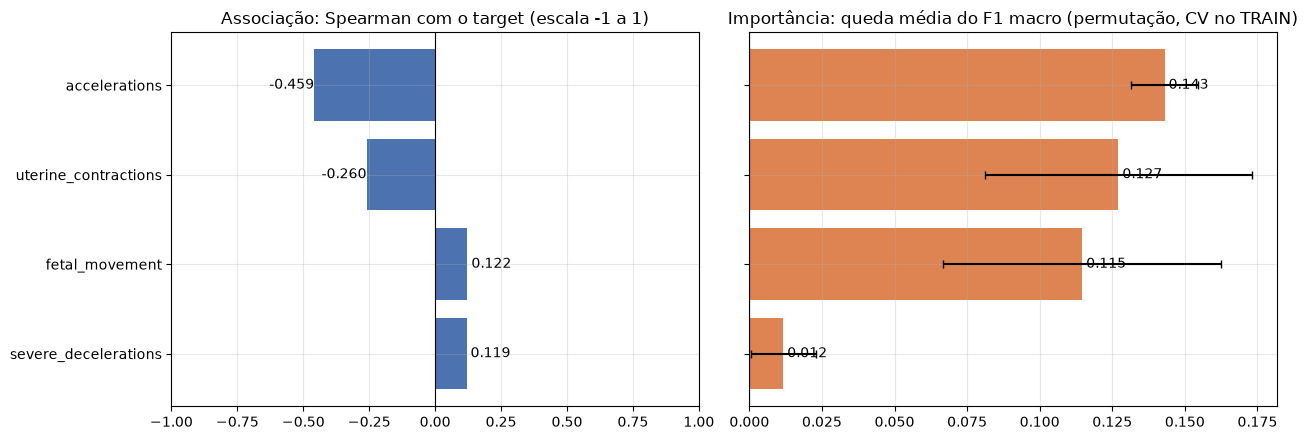

In [15]:
order = assoc_imp.index.tolist()[::-1]  # mesma ordem nos dois painéis
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].barh(order, assoc_imp.loc[order, "spearman"], color="#4c72b0")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlim(-1, 1)
axes[0].set_title("Associação: Spearman com o target (escala -1 a 1)")
for i, v in enumerate(assoc_imp.loc[order, "spearman"]):
    axes[0].text(v, i, f" {v:.3f}", va="center", ha="left" if v >= 0 else "right")

axes[1].barh(
    order,
    assoc_imp.loc[order, "perm_importance_mean"],
    xerr=assoc_imp.loc[order, "perm_importance_std"],
    color="#dd8452",
    capsize=3,
)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Importância: queda média do F1 macro (permutação, CV no TRAIN)")
for i, v in enumerate(assoc_imp.loc[order, "perm_importance_mean"]):
    axes[1].text(v, i, f" {v:.3f}", va="center")
fig.tight_layout()
save_fig(fig, "association_vs_importance")
plt.show()

## 10. Síntese e próximos passos

As interpretações abaixo devem ser lidas junto das tabelas e gráficos gerados na
execução (salvos em `reports/figures/eda_*.png` e `reports/metrics/eda_*.csv`).

**Implicações para a modelagem (decisões de protocolo):**
- Target **desbalanceado**: avaliar com F1 macro (principal), recall/precision por
  classe — com atenção ao **recall da classe Patológico** — e matriz de confusão; acurácia isolada é enganosa.
- A grade da Random Forest compara pesos padrão e `class_weight="balanced"`.
- As quatro features discretas seguem para Random Forest e XGBoost com imputação pela mediana.
- A CV estratificada aninhada no TRAIN avalia as duas buscas. O TEST é reservado à receita congelada.

**Próximo passo:** rodar a GridSearchCV (`python -m saude_fetal.train` ou notebook `02_model_training`)
e analisar no `03_model_metrics` e no MLflow.